# Cinética del Plasma en Pulverización Catódica (*Magnetron Sputtering*) para Películas Delgadas de AlN

Este cuaderno modela el transporte balístico frente al régimen difusivo de especies pulverizadas en atmósfera reactiva $\text{Ar}/\text{N}_2$ durante el crecimiento de películas delgadas de Nitruro de Aluminio ($\text{AlN}$).

### Fundamento Físico
1. **Camino Libre Medio ($\lambda$):** Distancia promedio recorrida por una especie antes de sufrir una colisión elástica con el gas de trabajo:
   $$\lambda = \frac{k_B T}{\sqrt{2}\,4\pi r_{\text{mean}}^2 P}$$
2. **Probabilidad de Colisión ($P_c$):** Fracción de especies dispersadas antes de alcanzar el sustrato ubicado a una distancia blanco–sustrato $D_{TS}$:
   $$P_c = 1 - \exp\left(-\frac{D_{TS}}{\lambda}\right)$$

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Detectar la raíz del repositorio y configurar rutas
ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

IMAGES_DIR = ROOT_DIR / "images"
IMAGES_DIR.mkdir(parents=True, exist_ok=True)

from src.plasma_kinetics import (
    TORR_TO_PA,
    calculate_mean_free_path,
    calculate_collision_probability,
)

## 1. Barrido Paramétrico en Unidades de Cámara (Torr / mTorr)

Evaluación del camino libre medio y la probabilidad de colisión en el rango operativo típico de cámara ($1\text{ a }30\text{ mTorr}$), explorando temperaturas de sustrato entre $500\ ^\circ\text{C}$ y $650\ ^\circ\text{C}$ y distancias blanco–sustrato $D_{TS} \in \{6, 8, 10, 12\}\text{ cm}$.

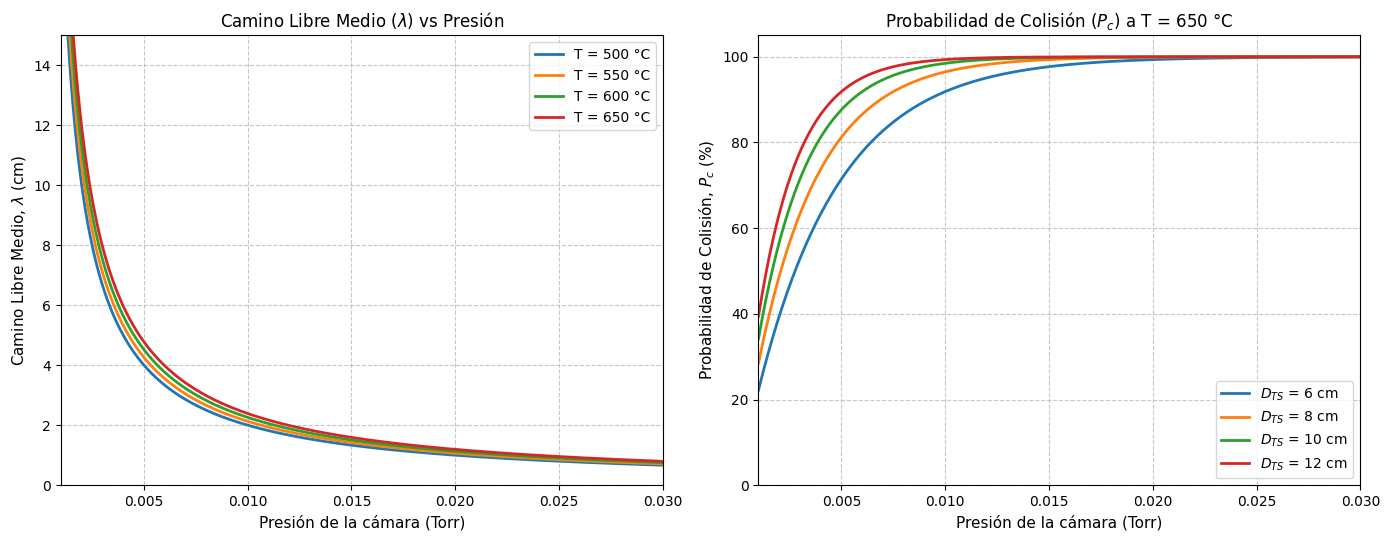

In [2]:
# Parámetros experimentales en unidades de cámara
r_mean = 1.5e-10  # Radio efectivo promedio Ar/N2 (m)
T_C = np.array([500, 550, 600, 650])
T_K = T_C + 273.15
D_TS_cm = np.array([6, 8, 10, 12])
D_TS_m = D_TS_cm / 100.0

# Rango de presión: 0.001 a 0.030 Torr (1 a 30 mTorr)
P_torr = np.linspace(0.001, 0.030, 500)
P_pa = P_torr * TORR_TO_PA

# Cálculo mediante el módulo src.plasma_kinetics
lambda_torr = {T: calculate_mean_free_path(T, P_pa, r_mean=r_mean) for T in T_K}
Pc_torr_650 = {
    D: calculate_collision_probability(D, lambda_torr[650 + 273.15]) for D in D_TS_m
}

# Visualización
plt.style.use("default")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
colores = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

for i, (T_celsius, T_kelvin) in enumerate(zip(T_C, T_K)):
    ax1.plot(
        P_torr,
        lambda_torr[T_kelvin] * 100,
        linewidth=2,
        color=colores[i],
        label=f"T = {T_celsius} °C",
    )

ax1.set_title(r"Camino Libre Medio ($\lambda$) vs Presión")
ax1.set_xlabel("Presión de la cámara (Torr)", fontsize=11)
ax1.set_ylabel(r"Camino Libre Medio, $\lambda$ (cm)", fontsize=11)
ax1.grid(True, linestyle="--", alpha=0.7)
ax1.legend(loc="upper right")
ax1.set_xlim(0.001, 0.030)
ax1.set_ylim(0, 15)

for D_cm, D_m in zip(D_TS_cm, D_TS_m):
    ax2.plot(
        P_torr,
        Pc_torr_650[D_m] * 100,
        linewidth=2,
        label=f"$D_{{TS}}$ = {D_cm} cm",
    )

ax2.set_title(r"Probabilidad de Colisión ($P_c$) a T = 650 °C")
ax2.set_xlabel("Presión de la cámara (Torr)", fontsize=11)
ax2.set_ylabel(r"Probabilidad de Colisión, $P_c$ (%)", fontsize=11)
ax2.grid(True, linestyle="--", alpha=0.7)
ax2.legend(loc="lower right")
ax2.set_xlim(0.001, 0.030)
ax2.set_ylim(0, 105)

plt.tight_layout()
plt.savefig(IMAGES_DIR / "sputtering_kinetics_torr.png", dpi=300, bbox_inches="tight")
plt.show()

## 2. Modelo Estandarizado en Sistema Internacional (Pa y K)

Análisis comparativo en unidades del Sistema Internacional ($P \in [0.1, 4.0]\text{ Pa}$) para geometrías compactas de deposición ($D_{TS} \in \{3, 4, 5\}\text{ cm}$) a $T = 873.15\text{ K}$ ($600\ ^\circ\text{C}$) y $T = 923.15\text{ K}$ ($650\ ^\circ\text{C}$).

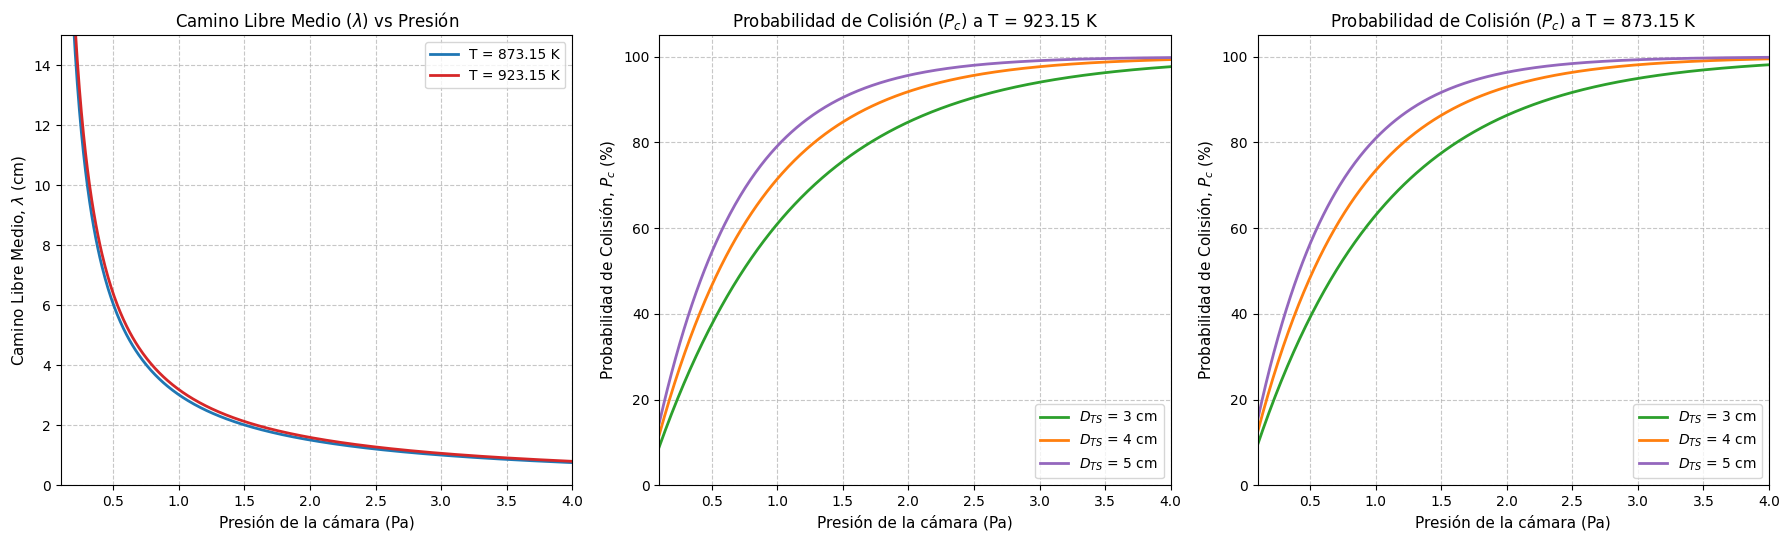

In [3]:
# Parámetros en Sistema Internacional (SI)
T_K_si = np.array([873.15, 923.15])
D_TS_cm_si = np.array([3, 4, 5])
D_TS_m_si = D_TS_cm_si / 100.0
P_pa_si = np.linspace(0.1, 4.0, 500)

# Cálculos de camino libre medio y probabilidad de colisión
lambda_si = {T: calculate_mean_free_path(T, P_pa_si, r_mean=r_mean) for T in T_K_si}
Pc_923 = {D: calculate_collision_probability(D, lambda_si[923.15]) for D in D_TS_m_si}
Pc_873 = {D: calculate_collision_probability(D, lambda_si[873.15]) for D in D_TS_m_si}

# Visualización de 3 paneles
plt.style.use("default")
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5.5))

colores_T = ["#1f77b4", "#d62728"]
for i, T in enumerate(T_K_si):
    ax1.plot(
        P_pa_si,
        lambda_si[T] * 100,
        linewidth=2,
        color=colores_T[i],
        label=f"T = {T} K",
    )

ax1.set_title(r"Camino Libre Medio ($\lambda$) vs Presión")
ax1.set_xlabel("Presión de la cámara (Pa)", fontsize=11)
ax1.set_ylabel(r"Camino Libre Medio, $\lambda$ (cm)", fontsize=11)
ax1.grid(True, linestyle="--", alpha=0.7)
ax1.legend(loc="upper right")
ax1.set_xlim(0.1, 4.0)
ax1.set_ylim(0, 15)

colores_D = ["#2ca02c", "#ff7f0e", "#9467bd"]
for i, D_cm in enumerate(D_TS_cm_si):
    D_m = D_cm / 100.0
    ax2.plot(
        P_pa_si,
        Pc_923[D_m] * 100,
        linewidth=2,
        color=colores_D[i],
        label=f"$D_{{TS}}$ = {D_cm} cm",
    )

ax2.set_title(r"Probabilidad de Colisión ($P_c$) a T = 923.15 K")
ax2.set_xlabel("Presión de la cámara (Pa)", fontsize=11)
ax2.set_ylabel(r"Probabilidad de Colisión, $P_c$ (%)", fontsize=11)
ax2.grid(True, linestyle="--", alpha=0.7)
ax2.legend(loc="lower right")
ax2.set_xlim(0.1, 4.0)
ax2.set_ylim(0, 105)

for i, D_cm in enumerate(D_TS_cm_si):
    D_m = D_cm / 100.0
    ax3.plot(
        P_pa_si,
        Pc_873[D_m] * 100,
        linewidth=2,
        color=colores_D[i],
        label=f"$D_{{TS}}$ = {D_cm} cm",
    )

ax3.set_title(r"Probabilidad de Colisión ($P_c$) a T = 873.15 K")
ax3.set_xlabel("Presión de la cámara (Pa)", fontsize=11)
ax3.set_ylabel(r"Probabilidad de Colisión, $P_c$ (%)", fontsize=11)
ax3.grid(True, linestyle="--", alpha=0.7)
ax3.legend(loc="lower right")
ax3.set_xlim(0.1, 4.0)
ax3.set_ylim(0, 105)

plt.tight_layout()
plt.savefig(IMAGES_DIR / "sputtering_mfp_collision_si.png", dpi=300, bbox_inches="tight")
plt.show()